In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
df = pd.read_csv(r"C:\Users\Josephine Mackylah\Desktop\Kenya market prices\data\food-prices-kenya.csv")
df.head()
df.columns


Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [4]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [5]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
2316,2016-11-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,3000.00,29.53
273,2018-12-15,Eastern,Kitui,Kitui,Beans,Retail,KG,66.10,0.65
2237,2010-03-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,2400.00,31.29
1089,2015-08-15,Rift Valley,Baringo,Marigat,Maize,Retail,KG,46.00,0.45
171,2010-06-15,Eastern,Kitui,Kitui,Beans,Retail,KG,40.00,0.50
238,2016-01-15,Eastern,Kitui,Kitui,Beans,Retail,KG,73.00,0.71
2542,2008-03-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,1419.00,21.79
1856,2011-02-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,4677.00,57.49
1241,2014-12-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,48.80,0.54
1746,2015-09-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,5795.00,54.88


In [6]:
#turn the date column into real date
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(20, random_state=42)

859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
2518   2006-03-15
2201   2007-02-15
798    2010-02-15
1110   2017-06-15
1900   2014-10-15
1364   2011-05-15
1102   2016-10-15
1601   2017-05-15
1179   2009-06-15
2030   2006-10-15
677    2014-01-15
1117   2018-01-15
1607   2017-11-15
1820   2008-02-15
2104   2013-01-15
Name: date, dtype: datetime64[us]

In [7]:
# add year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
1798,2006-04-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,4310.0,60.63,2006,4
1837,2009-07-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,4500.0,58.37,2009,7
979,2011-05-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,57.0,0.66,2011,5
1311,2006-12-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2600.0,37.38,2006,12
1873,2012-07-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,5290.0,62.98,2012,7


In [8]:
#fill the missing county and region for the market that has none.
df["county"].isna().sum()
df["region"].isna().sum()

np.int64(59)

In [9]:
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

Series([], dtype: int64)


In [12]:
#How many rows, markets and commodities does the file have, and what are the first and last dates
print(df.shape)

(2742, 11)


In [13]:
df_sorted = df.sort_values("date")
df_sorted.iloc[0]["date"]                
df_sorted.iloc[-1]["date"]
df.head(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5


In [14]:
#sorting the date from the earliest to the latest date
highest_date = df["date"].max()
print(highest_date)
lowest_date = df["date"].min()
print(lowest_date)

2019-12-15 00:00:00
2006-01-15 00:00:00


In [15]:


""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""
# df_wholesale = df[df["price_type"] == "wholesale" and df["unit"] == "90 KG"].copy()
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()

# df["price_per_kg"] = np.where(df["price_type"] == "wholesale", df["price"] / 90, df["price"])
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [16]:


# wholesale 90KG bags only
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()

df_wholesale.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [17]:
# this code splits the dataset into a retail-only dataframe
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [18]:
#we are finding the price for a single kg of maize by dividing the wholesale price by 90 ---> retail_price
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [19]:
#average for the maize commodity in the wholesale sales_price_per_kg
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(28.54230389890584)

In [20]:
#average for the maize commodity in the retail sales_price_per_kg
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(47.91992670157068)

In [21]:
#Maize prices over the years
#Calculate the average wholesale maize price per bag for each year and the year-on-year change. Plot the yearly average as a line chart with the price in KES on the y-axis.
# Which year had the highest average wholesale maize price?
# Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?


df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy()
df_maize.head(10)

yearly_avg = yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index()
yearly_avg

,year,price_kes
0,2006,1395.036875
1,2007,1207.450625
2,2008,1906.319149
3,2009,2513.271875
4,2010,1773.951458
5,2011,3020.218750
6,2012,3173.782609
7,2013,2962.458333
8,2014,2993.717083
9,2015,2690.149833


In [22]:
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg

,year,avg_price_kes
0,2006,1395.036875
1,2007,1207.450625
2,2008,1906.319149
3,2009,2513.271875
4,2010,1773.951458
5,2011,3020.218750
6,2012,3173.782609
7,2013,2962.458333
8,2014,2993.717083
9,2015,2690.149833


In [23]:
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg

,year,avg_price_kes,yoy_change_kes
0,2006,1395.036875,NaN
1,2007,1207.450625,-187.586250
2,2008,1906.319149,698.868524
3,2009,2513.271875,606.952726
4,2010,1773.951458,-739.320417
5,2011,3020.218750,1246.267292
6,2012,3173.782609,153.563859
7,2013,2962.458333,-211.324275
8,2014,2993.717083,31.258750
9,2015,2690.149833,-303.567250


In [24]:
# Which year had the highest average wholesale maize price?
yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax(),'year']


np.int32(2017)

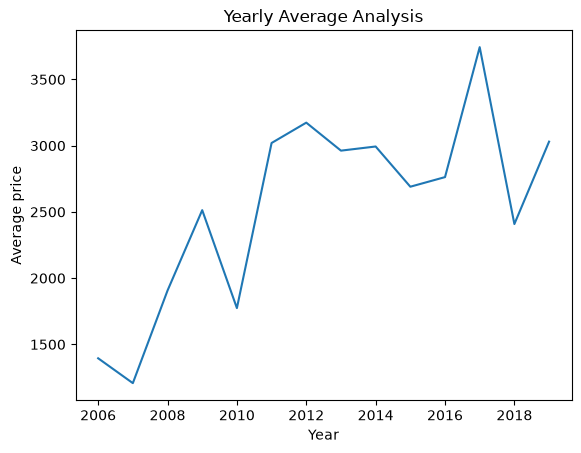

In [26]:
plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"])
plt.xlabel("Year")
plt.ylabel("Average price")
plt.title("Yearly Average Analysis")
plt.show()